In [1]:
import numpy as np
import netCDF4 as nc
import matplotlib.pyplot as plt

# Impact of the wave mixing, using the TKE-1 eq closure

### WM  -> ue + us term in the momentum equation (diffusion)
### TKE -> ue + us term in the shear term in tke closure

In [2]:
def get_var(file_name:str, var_name: str, cplx: bool = False, kt:int | None = None):
    with nc.Dataset(file_name) as data:
        # --- Variables ---
        if cplx:
            var_m = data[f'{var_name}_mean_re'][:] + 1j*data[f'{var_name}_mean_im'][:]
            var_v = data[f'{var_name}_var_re'][:]  + 1j*data[f'{var_name}_var_im'][:]
        else:
            var_m = data[f'{var_name}_mean'][:]
            var_v = data[f'{var_name}_var'][:]
            
        # --- Coordinates ---
        z_c = data['zc'][:]
        z_w = data['zw'][:]
        t   = data['time'][:]
        
        # --- Find shape ---
        z = z_c if var_m.shape[1] == z_c.shape[0] else z_w
        
    if kt is not None:
        return z, var_m[kt, :], var_v[kt, :]
    else:
        return z, t, var_m, var_v
    
def plt_var(ax, z, var_m, var_v, label = None):
    ax.plot(var_m.real, z, label = label)
    ax.fill_betweenx(z, var_m.real - var_v.real**0.5, 
                         var_m.real + var_v.real**0.5,
                         alpha = 0.2)

In [3]:
OUTPUT_FOLDER = '/home/mnex/Desktop/1DV_FD/experiments/Wave_mixing/output/'
F0 = OUTPUT_FOLDER + 'W-M.nc'
F1 = OUTPUT_FOLDER + 'W-M_wm.nc'
F2 = OUTPUT_FOLDER + 'W-M_tke.nc'
F3 = OUTPUT_FOLDER + 'W-M_wm_tke.nc'

# Ekman velocities
z_w, ue_m,        ue_v        = get_var(F0, 'ue', kt=-1, cplx=True)
z_w, ue_m_wm,     ue_v_wm     = get_var(F1, 'ue', kt=-1, cplx=True)
z_w, ue_m_tke,    ue_v_tke    = get_var(F2, 'ue', kt=-1, cplx=True)
z_w, ue_m_wm_tke, ue_v_wm_tke = get_var(F3, 'ue', kt=-1, cplx=True)

# Mixing coefficient
z_w, azm_m,        azm_v        = get_var(F0, 'az_m', kt=-1)
z_w, azm_m_wm,     azm_v_wm     = get_var(F1, 'az_m', kt=-1)
z_w, azm_m_tke,    azm_v_tke    = get_var(F2, 'az_m', kt=-1)
z_w, azm_m_wm_tke, azm_v_wm_tke = get_var(F3, 'az_m', kt=-1)

# Temperature
z_c, T_m,        T_v        = get_var(F0, 'temp', kt=-1)
z_c, T_m_wm,     T_v_wm     = get_var(F1, 'temp', kt=-1)
z_c, T_m_tke,    T_v_tke    = get_var(F2, 'temp', kt=-1)
z_c, T_m_wm_tke, T_v_wm_tke = get_var(F3, 'temp', kt=-1)

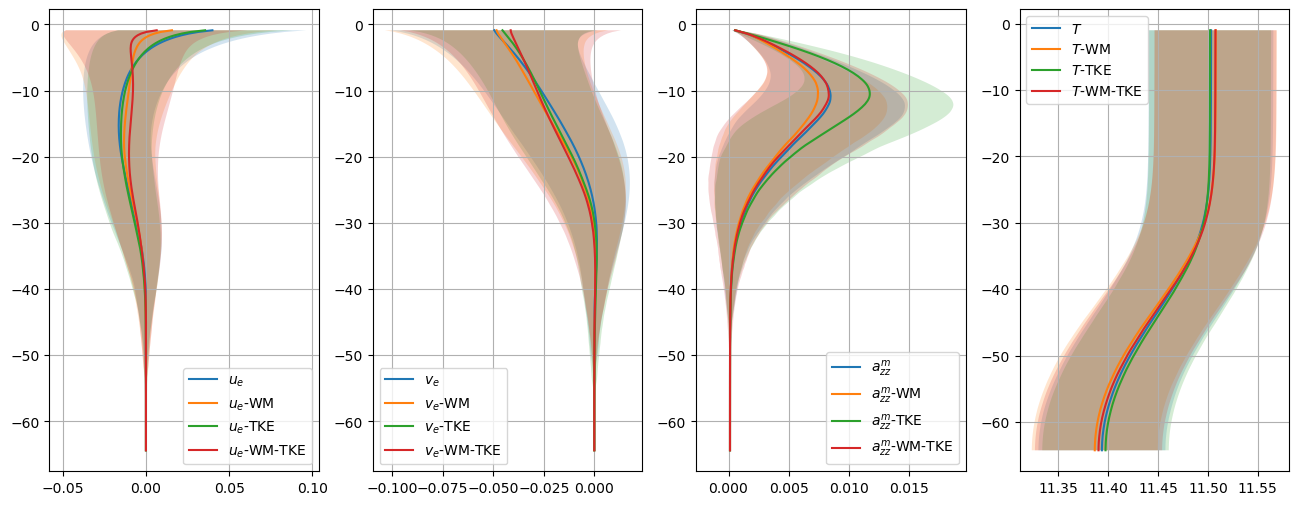

In [4]:
fig, ax = plt.subplots(1, 4, figsize=(16, 6))

plt_var(ax[0], z_w, ue_m.real,        ue_v.real,        label = r'$u_e$')
plt_var(ax[0], z_w, ue_m_wm.real,     ue_v_wm.real,     label = r'$u_e$-WM')
plt_var(ax[0], z_w, ue_m_tke.real,    ue_v_tke.real,    label = r'$u_e$-TKE')
plt_var(ax[0], z_w, ue_m_wm_tke.real, ue_v_wm_tke.real, label = r'$u_e$-WM-TKE')
ax[0].grid()
ax[0].legend()

plt_var(ax[1], z_w, ue_m.imag,        ue_v.imag,        label = r'$v_e$')
plt_var(ax[1], z_w, ue_m_wm.imag,     ue_v_wm.imag,     label = r'$v_e$-WM')
plt_var(ax[1], z_w, ue_m_tke.imag,    ue_v_tke.imag,    label = r'$v_e$-TKE')
plt_var(ax[1], z_w, ue_m_wm_tke.imag, ue_v_wm_tke.imag, label = r'$v_e$-WM-TKE')
ax[1].grid()
ax[1].legend()

plt_var(ax[2], z_w, azm_m,        azm_v,        label = r'$a_{zz}^m$')
plt_var(ax[2], z_w, azm_m_wm,     azm_v_wm,     label = r'$a_{zz}^m$-WM')
plt_var(ax[2], z_w, azm_m_tke,    azm_v_tke,     label = r'$a_{zz}^m$-TKE')
plt_var(ax[2], z_w, azm_m_wm_tke, azm_v_wm_tke, label = r'$a_{zz}^m$-WM-TKE')
ax[2].grid()
ax[2].legend()

plt_var(ax[3], z_c, T_m,        T_v,        label = r'$T$')
plt_var(ax[3], z_c, T_m_wm,     T_v_wm,     label = r'$T$-WM')
plt_var(ax[3], z_c, T_m_tke,    T_v_tke,    label = r'$T$-TKE')
plt_var(ax[3], z_c, T_m_wm_tke, T_v_wm_tke, label = r'$T$-WM-TKE')
ax[3].grid()
ax[3].legend()